# WellbeingIQ · Notebook 4: Explainable AI (SHAP + LIME)
**Input:** `wellbeingiq_model.joblib`, `model_card.json`, `X_train.csv`, `X_test.csv`, `y_test.csv`, helper modules `wellbeing_features.py` and `wellbeing_explain.py`.

> **Data note:** the data is **synthetic**. Explanations describe what the model learned from simulated students, not causes in real students. Not a medical tool.

**Why explanations matter here:** a prediction like "At-Risk" is only useful if the student (and the reviewer) can see *which habits* pushed it there. This notebook
1. explains the model globally (which habits matter overall),
2. explains single students (why *this* student got *this* result),
3. cross-checks SHAP against LIME,
4. builds the explanation function and a **reliability flag** that the GenAI wellness coach and the dashboard will use.

**How to read SHAP here:** each value is the contribution of a habit to the *At-Risk log-odds* relative to the average student. Positive = pushes toward At-Risk, negative = protects. Contributions add up exactly to the model's score for that student (checked below).

In [1]:
import pandas as pd, numpy as np, json, joblib, shap, warnings, matplotlib.pyplot as plt, seaborn as sns
from sklearn.model_selection import cross_val_predict, StratifiedKFold
from lime.lime_tabular import LimeTabularExplainer
from wellbeing_explain import WellbeingExplainer, LABELS, group_of
warnings.filterwarnings('ignore'); sns.set_theme(style='whitegrid'); RS=42
ex = WellbeingExplainer()                     # loads model + builds the SHAP explainer on the training data
card = json.load(open('model_card.json')); ORDER = card['classes_order']
X_train = pd.read_csv('X_train.csv')[ex.features]; X_test = pd.read_csv('X_test.csv')[ex.features]
y_train = pd.read_csv('y_train.csv').iloc[:,0]; y_test = pd.read_csv('y_test.csv').iloc[:,0]
Xtr_t, Xte_t = ex.transform(X_train), ex.transform(X_test)
print('model:', card['model'], '| model features:', len(ex.features), '| after encoding/engineering:', Xte_t.shape[1])
print('classes in model:', ex.classes)

/usr/local/lib/python3.12/dist-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


model: Logistic Regression | model features: 23 | after encoding/engineering: 54
classes in model: ['At-Risk', 'Good', 'Moderate']


## 1. SHAP values and a correctness check

In [2]:
sv = ex.shap_values(Xte_t)                      # (students, encoded features, classes)
ai = ex.classes.index('At-Risk')
recon = ex.explainer.expected_value + sv.sum(1)
print('max |baseline + sum(SHAP) - model score|:', float(np.abs(recon - ex.clf.decision_function(Xte_t)).max()))
G = ex.grouped(sv[:,:,ai])                      # SHAP for At-Risk, summed into readable factors
print('readable factors:', G.shape[1])

max |baseline + sum(SHAP) - model score|: 3.552713678800501e-15
readable factors: 24


Contributions add up to the model's own score (difference is numerical noise), so the explanations are exact for this model, not approximations.

## 2. Global view: which habits matter most?

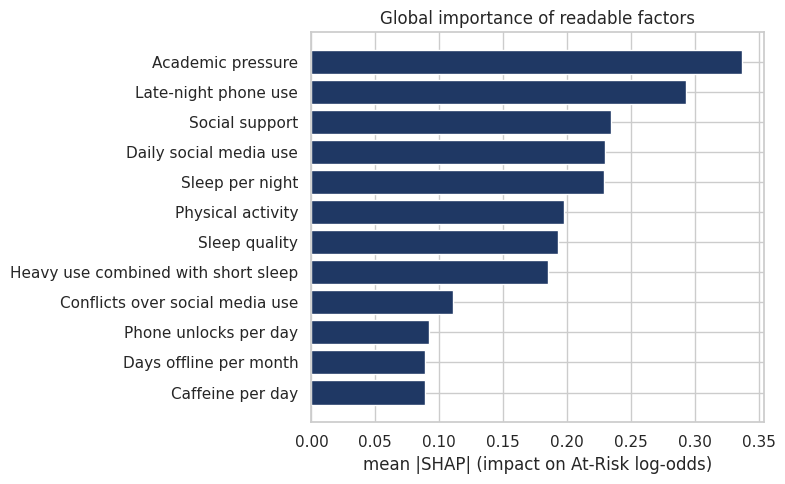

,mean |SHAP|
Academic_Pressure,0.337
Late_Night_Usage_Hours,0.293
Social_Support_Score,0.234
Avg_Daily_Usage_Hours,0.230
Sleep_Hours_Per_Night,0.228
Physical_Activity_Hours,0.198
Sleep_Quality,0.193
Usage_Sleep_Combination,0.185
Conflicts_Over_Social_Media,0.110
Daily_Unlocks,0.092


In [3]:
imp = G.abs().mean().sort_values(ascending=False)
top = imp.head(12).iloc[::-1]
plt.figure(figsize=(8,5)); plt.barh([LABELS.get(k,k) for k in top.index], top.values, color='#1F3864')
plt.xlabel('mean |SHAP| (impact on At-Risk log-odds)'); plt.title('Global importance of readable factors'); plt.tight_layout(); plt.show()
imp.round(3).head(12).to_frame('mean |SHAP|')

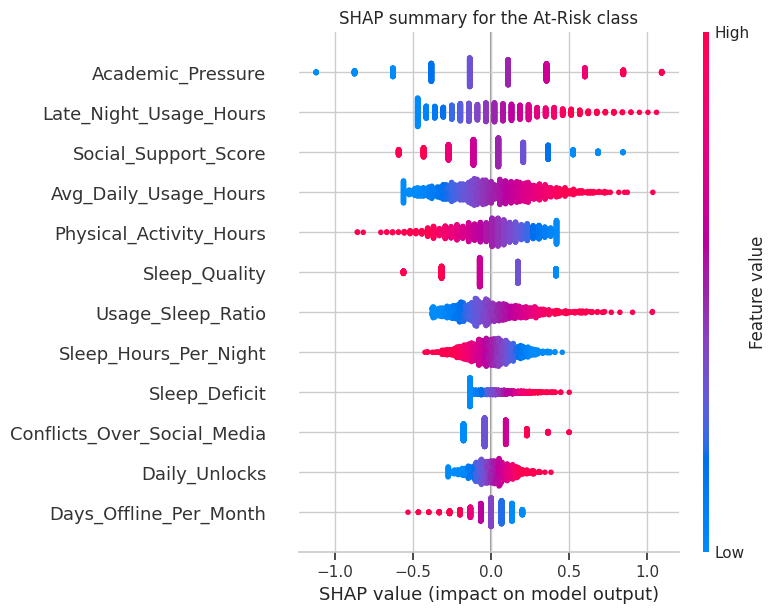

In [4]:
# beeswarm on the encoded features for the At-Risk class (colour = feature value, x = push toward / away from At-Risk)
names = [n.replace('num__','').replace('cat__','') for n in ex.names]
shap.summary_plot(sv[:,:,ai], Xte_t, feature_names=names, max_display=12, show=False); plt.title('SHAP summary for the At-Risk class'); plt.tight_layout(); plt.show()

**Cross-check with the EDA (Notebook 2):** the habits that EDA flagged (usage, late-night use, sleep, activity, social support, academic pressure) should lead here, and country / gender / platform should sit near the bottom.

In [5]:
eda = ['Avg_Daily_Usage_Hours','Late_Night_Usage_Hours','Sleep_Hours_Per_Night','Physical_Activity_Hours','Social_Support_Score','Academic_Pressure']
dem = ['Country','Gender','Most_Used_Platform','Purpose_Of_Use','Academic_Level','Residence']
rank = imp.rank(ascending=False).astype(int)
pd.concat([pd.DataFrame({'Factor':eda,'Type':'habit flagged in EDA','SHAP rank (1 = most important of %d)'%len(imp):rank[eda].values}),
           pd.DataFrame({'Factor':dem,'Type':'demographic / platform','SHAP rank (1 = most important of %d)'%len(imp):rank[dem].values})]).reset_index(drop=True)

,Factor,Type,SHAP rank (1 = most important of 24)
0,Avg_Daily_Usage_Hours,habit flagged in EDA,4
1,Late_Night_Usage_Hours,habit flagged in EDA,2
2,Sleep_Hours_Per_Night,habit flagged in EDA,5
3,Physical_Activity_Hours,habit flagged in EDA,6
4,Social_Support_Score,habit flagged in EDA,3
5,Academic_Pressure,habit flagged in EDA,1
6,Country,demographic / platform,18
7,Gender,demographic / platform,20
8,Most_Used_Platform,demographic / platform,19
9,Purpose_Of_Use,demographic / platform,17


## 3. Dependence: where does the risk contribution turn on?

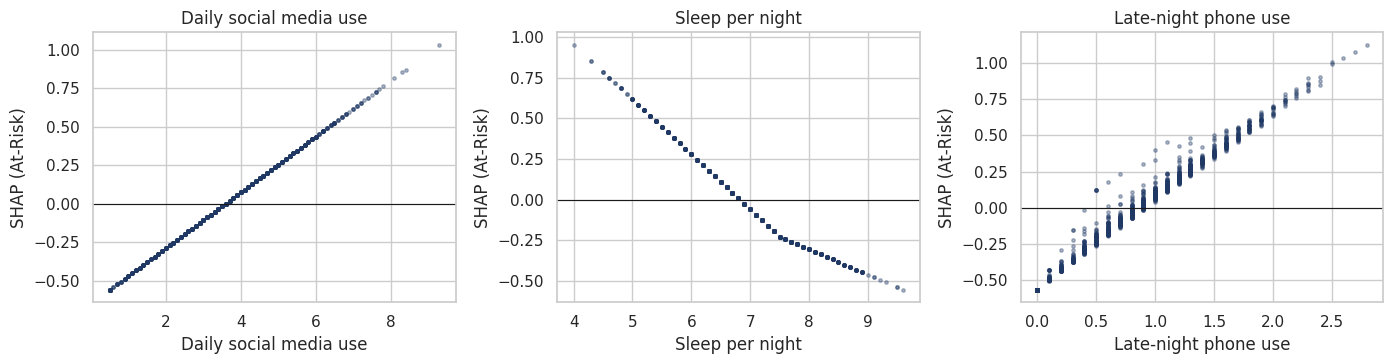

In [6]:
fig,ax = plt.subplots(1,3,figsize=(14,3.8))
for a,c in zip(ax,['Avg_Daily_Usage_Hours','Sleep_Hours_Per_Night','Late_Night_Usage_Hours']):
    a.scatter(X_test[c], G[c], s=6, alpha=.35, color='#1F3864'); a.axhline(0,color='k',lw=.8); a.set_xlabel(LABELS[c]); a.set_ylabel('SHAP (At-Risk)')
    a.set_title(LABELS[c])
plt.tight_layout(); plt.show()

The pattern is close to a straight line: each extra hour of use or late-night use adds a steady amount of risk, and each extra hour of sleep takes a steady amount away. Because the model is linear, there are no sharp jumps in the model itself. The jumps seen in the EDA come from how risk bands are cut.

## 4. Explaining individual students

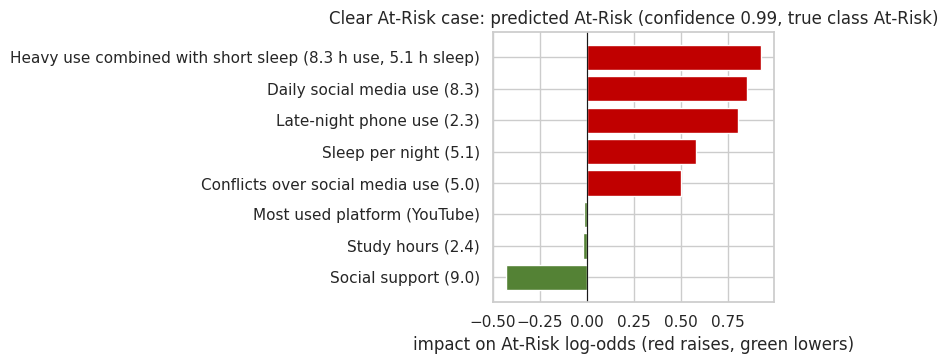

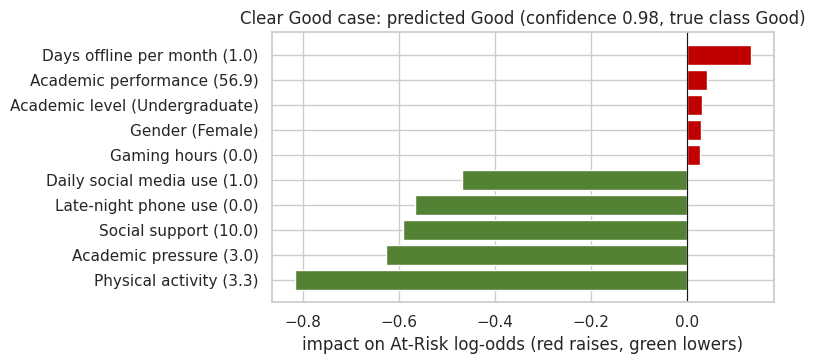

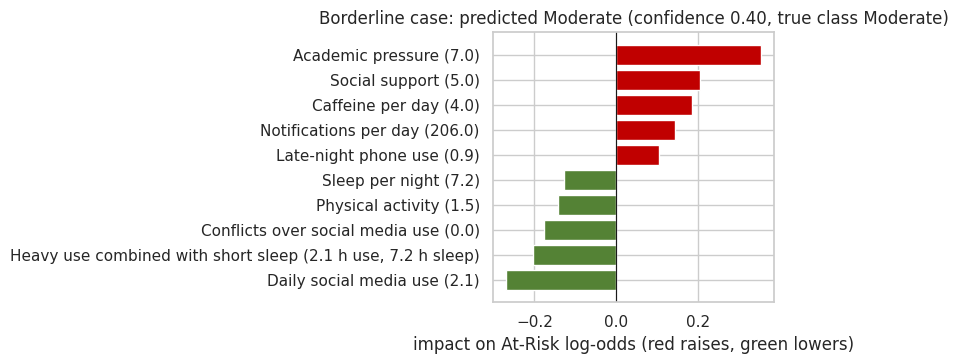

In [7]:
proba = ex.pipe.predict_proba(X_test)
picks = {'Clear At-Risk case': int(np.argmax(proba[:,ai])),
         'Clear Good case': int(np.argmax(proba[:,ex.classes.index('Good')])),
         'Borderline case': int(np.argmin(np.abs(proba.max(1) - 0.40)))}
def plot_local(i, title):
    e = ex.explain(X_test.iloc[i].to_dict(), top_k=5)
    rows = e['risk_drivers'] + e['protective_factors']; rows = sorted(rows, key=lambda r:r['impact'])
    plt.figure(figsize=(8,3.8)); plt.barh([f"{r['label']} ({r['value']})" for r in rows],[r['impact'] for r in rows],color=['#548235' if r['impact']<0 else '#C00000' for r in rows])
    plt.axvline(0,color='k',lw=.8); plt.title(f"{title}: predicted {e['predicted_category']} (confidence {e['confidence']:.2f}, true class {y_test.iloc[i]})"); plt.xlabel('impact on At-Risk log-odds (red raises, green lowers)'); plt.tight_layout(); plt.show()
for t,i in picks.items(): plot_local(i,t)

## 5. Cross-check with LIME (a second, independent explainer)

In [8]:
cat_idx = [i for i,n in enumerate(ex.names) if n.startswith('cat__')]
lime_ex = LimeTabularExplainer(Xtr_t, feature_names=ex.names, class_names=ex.classes, mode='classification', categorical_features=cat_idx, discretize_continuous=True, random_state=RS)
rng = np.random.default_rng(RS); idx = rng.choice(len(X_test), 25, replace=False); top1=[]; top3=[]
for i in idx:
    e = lime_ex.explain_instance(Xte_t[i], ex.clf.predict_proba, labels=[ai], num_features=12, num_samples=1500)
    lime_groups = []
    for f,w in sorted(e.as_list(label=ai), key=lambda t:-abs(t[1])):
        g = next((group_of(n, ex.cat_cols) for n in ex.names if f.startswith(n) or n in f), f)
        if g not in lime_groups: lime_groups.append(g)
    shap_groups = list(G.iloc[i].abs().sort_values(ascending=False).index[:3])
    top1.append(lime_groups[0]==shap_groups[0]); top3.append(len(set(lime_groups[:3]) & set(shap_groups))/3)
print(f'SHAP vs LIME over 25 students: same #1 factor in {np.mean(top1):.0%} of cases; average overlap of the top-3 factors {np.mean(top3):.2f}')

SHAP vs LIME over 25 students: same #1 factor in 52% of cases; average overlap of the top-3 factors 0.73


## 6. Reliability flag for the GenAI coach (fallback for unreliable predictions)

In [9]:
skf = StratifiedKFold(5, shuffle=True, random_state=RS)
P_oof = cross_val_predict(ex.pipe, X_train, y_train, cv=skf, method='predict_proba')
conf_oof = P_oof.max(1); pred_oof = np.array(ex.classes)[P_oof.argmax(1)]
rows=[]
for t in [0.40,0.45,0.50,0.55,0.60,0.65]:
    keep = conf_oof>=t; rows.append({'confidence threshold':t,'share of students kept':keep.mean(),'accuracy on kept':(pred_oof[keep]==y_train.values[keep]).mean(),'accuracy on flagged':(pred_oof[~keep]==y_train.values[~keep]).mean() if (~keep).any() else np.nan})
tab = pd.DataFrame(rows).round(3); display(tab)

,confidence threshold,share of students kept,accuracy on kept,accuracy on flagged
0,0.40,0.998,0.617,0.778
1,0.45,0.936,0.621,0.564
2,0.50,0.713,0.638,0.566
3,0.55,0.538,0.653,0.575
4,0.60,0.434,0.681,0.568
5,0.65,0.365,0.707,0.566


In [10]:
# rule: flag a prediction as 'uncertain' below the lowest threshold that keeps at least half the students and gives >= 70% accuracy on the rest
ok = tab[(tab['share of students kept']>=0.5)&(tab['accuracy on kept']>=0.70)]
T = float(ok['confidence threshold'].iloc[0]) if len(ok) else 0.55
json.dump({'uncertainty_confidence_threshold':T}, open('explain_config.json','w'))
ex.uncertain_below = T
conf_te = proba.max(1); pred_te = np.array(ex.classes)[proba.argmax(1)]; keep = conf_te>=T
print(f'Chosen threshold: {T}')
print(f'TEST set: {keep.mean():.0%} of predictions are confident -> accuracy {(pred_te[keep]==y_test.values[keep]).mean():.3f}; flagged uncertain ({(~keep).mean():.0%}) -> accuracy {(pred_te[~keep]==y_test.values[~keep]).mean():.3f}')

Chosen threshold: 0.55
TEST set: 55% of predictions are confident -> accuracy 0.666; flagged uncertain (45%) -> accuracy 0.586


When a prediction is flagged, the GenAI coach will use cautious wording ("this is a rough estimate") and avoid firm statements. This implements the proposal's *uncertainty wording and fallback for unreliable predictions*.

## 7. The explanation function the coach and dashboard will call

In [11]:
example = ex.explain(X_test.iloc[picks['Clear At-Risk case']].to_dict(), top_k=3)
print(json.dumps(example, indent=2))

{
  "predicted_category": "At-Risk",
  "probabilities": {
    "At-Risk": 0.988,
    "Good": 0.0,
    "Moderate": 0.012
  },
  "confidence": 0.988,
  "uncertain": false,
  "risk_drivers": [
    {
      "feature": "Usage_Sleep_Combination",
      "label": "Heavy use combined with short sleep",
      "value": "8.3 h use, 5.1 h sleep",
      "impact": 0.929
    },
    {
      "feature": "Avg_Daily_Usage_Hours",
      "label": "Daily social media use",
      "value": 8.3,
      "impact": 0.853
    },
    {
      "feature": "Late_Night_Usage_Hours",
      "label": "Late-night phone use",
      "value": 2.3,
      "impact": 0.804
    }
  ],
  "protective_factors": [
    {
      "feature": "Social_Support_Score",
      "label": "Social support",
      "value": 9.0,
      "impact": -0.432
    },
    {
      "feature": "Study_Hours",
      "label": "Study hours",
      "value": 2.4,
      "impact": -0.023
    },
    {
      "feature": "Most_Used_Platform",
      "label": "Most used platform",
  

In [12]:
imp.round(4).rename('mean_abs_shap').to_csv('global_importance.csv')
print('saved: explain_config.json, global_importance.csv')

saved: explain_config.json, global_importance.csv


## 8. Findings and honest reading

| Check | Result |
|---|---|
| SHAP correctness | baseline + sum of SHAP reproduces the model score to about 1e-15, so explanations are exact for this model |
| Most important factors (mean abs SHAP) | Academic pressure 0.337, late-night phone use 0.293, social support 0.234, daily social media use 0.230, sleep per night 0.228, physical activity 0.198, sleep quality 0.193, heavy use combined with short sleep 0.185 |
| Demographics and platform | Country, gender, platform, purpose, level and residence rank 15 to 20 out of 24, so they barely matter. This matches the EDA (Notebook 2). |
| SHAP vs LIME (25 students) | same top factor in 52% of cases, top-3 overlap 0.73 |
| Reliability flag | threshold 0.55; on the test set 55% of predictions are confident (accuracy 0.666) and 45% are flagged uncertain (accuracy 0.586) |

**How to read this**
- All six habits flagged in the EDA appear in the top six, and demographics sit near the bottom, so the model and the EDA tell the same story.
- **Academic pressure leads** in SHAP. The EDA compared it less closely, so this is a useful addition. Its weight comes from how the simulated score was built, so do not read it as a finding about real students.
- Contributions look close to straight lines (Section 3): in a linear model each extra hour of use adds a steady amount of risk and each extra hour of sleep removes a steady amount.
- **LIME agrees with SHAP only partly.** For a linear model SHAP is exact, while LIME is a sampled approximation, and overlapping features (usage, unlocks, notifications) share credit differently. SHAP is therefore the primary explainer, and LIME is a sanity check that finds broadly the same factors.
- **The reliability flag is a soft signal only.** No threshold reached the target of 70% accuracy while keeping half of the students, so the fallback value 0.55 was used. Flagged predictions are somewhat less accurate (0.586 vs 0.666), which is a real but modest difference. The coach should use cautious wording for flagged cases and should never present any prediction as certain.

**Limits:** synthetic data; explanations show what the model relies on, not what causes wellbeing; engineered and original habits overlap, which is why they are merged into readable factors.

**Next:** build the GenAI wellness coach on top of `WellbeingExplainer.explain(...)`, then the Streamlit dashboard.
